<a href="https://colab.research.google.com/github/alex-asf-don/data_analytics/blob/main/Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Лабораторная работа 3. Кластеризация методом DBSCAN. Сегментация потребителей леденцов.


Выполнена Дон Александром

In [1]:
from google.colab import files
files.upload()

Saving Леденцы.dat to Леденцы.dat


{'Леденцы.dat': b'V1;V2;V3;V4;V5;V6;V7;V8;V9;V10;V11\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;4;5;3;3;3;3;3;3;3\r\n5;4;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;4;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;4;5;4;3;3;3;3;3;3;3\r\n4;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;4;4;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;3;3;3;3\r\n5;5;5;4;3;3;3;2;3;3;3\r\n5;4;4;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;4;4;4\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n4;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3;3\r\n5;5;5;5;3;3;3;3;3;3

**Импорт библиотек**

In [59]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

**Описание и импорт данных**

Данные содержат оценки степени согласия респондентов с высказываниями, отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:

V1: Я потребляю леденцы, чтобы освежить дыхание

V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

V3: Я потребляю леденцы, чтобы освежить полость рта

V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

V5: Я потребляю леденцы как заменитель других кондитерских изделий

V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

V7: Леденцы помогают мне сконцентрироваться

V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

V11: Я потребляю леденцы для улучшения самочувствия

In [3]:
df = pd.read_csv('Леденцы.dat', sep =';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [4]:
df.shape

(338, 11)

In [5]:
df.dtypes

,0
V1,int64
V2,int64
V3,int64
V4,int64
V5,int64
V6,int64
V7,int64
V8,int64
V9,int64
V10,int64


In [6]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Все признаки измеряются по шкале от 2 до 5 баллов, поэтому стандартизация не нужна. Пропуски и выбросы отсутствуют.

### **Подбираем параметры модели DBSCAN**

Начинаем со значений по умолчанию (eps=0.5, min_samples=5, расстояние - Евклидово)

In [7]:
dbscan_1 = DBSCAN()
dbscan_1.fit(df)
dbscan_1.labels_

array([ 0,  1, -1,  1,  0,  1, -1,  1,  2, -1, -1, -1,  3, -1, -1,  3,  3,
        3,  3,  3,  3,  3, -1,  3,  3,  3,  3, -1, -1, -1,  2,  2,  0,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  4,  4,  4,  4,  4,  4,  4,  4, -1,
        4, -1,  2,  2,  2,  2,  2,  2,  2, -1, -1, -1,  2,  2, -1, -1,  2,
        2,  2,  2, -1,  2,  2,  2,  2, -1,  2,  2,  2, -1,  2,  2,  2,  2,
        1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  0, -1, -1,  0,  0,  0, -1,
       -1,  0,  0,  0,  2,  2,  2,  2, -1,  5, -1,  5,  5,  5,  6,  6,  5,
        5,  6,  5,  7, -1,  6,  7,  7,  5,  5,  5,  5,  5,  6,  5,  5,  5,
        5,  5,  6, -1,  5,  6,  5,  7,  6,  5, -1,  5,  6,  7,  5,  5,  5,
        5,  6,  5,  5,  5,  5,  5,  5,  6,  5,  5,  5,  5, -1,  5,  7,  5,
       -1,  5, -1,  6,  5,  5,  7, -1, -1,  8,  8,  8, -1, -1, -1, -1,  5,
        5, -1,  8, -1, -1, -1,  8,  8, -1, -1,  5,  5,  5,  5,  5,  7,  5,
       -1, -1,  6,  6,  5,  7, -1, -1, -1, -1, -1,  7, -1,  6,  9, 10, 11,
       10, 11,  9,  9,  9

In [8]:
table_ = pd.value_counts(pd.Series(dbscan_1.labels_))
table_.sort_index(inplace=True)
print(table_)

-1     60
 0     10
 1      5
 2     49
 3     12
 4      9
 5     49
 6     15
 7     10
 8      6
 9     37
 10    10
 11     5
 12     9
 13    52
Name: count, dtype: int64


/tmp/ipykernel_499/3773837758.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  table_ = pd.value_counts(pd.Series(dbscan_1.labels_))


Получилось 14 кластеров - очень много и 60 выбросов

Следовательно нужно повысить eps либо min_samples. Попробую повысить min_samples, по правилу min_samples = 2 * D, где D - количество признаков. Признаков - 11, следовательно min_samples = 22.

In [19]:
dbscan_2 = DBSCAN(eps = 0.5, metric = 'euclidean', min_samples = 22)
dbscan_2.fit(df)

table = pd.Series(dbscan_2.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1    151
 0     49
 1     49
 2     37
 3     52
Name: count, dtype: int64


Уменьшили количество кластеров, но количество выбросов только увеличилось. Задал слишком большой min_samples. Попробую min_samples = D + 1, min_samples = 12.

In [25]:
dbscan_3 = DBSCAN(eps = 0.5, metric = 'euclidean', min_samples = 12)
dbscan_3.fit(df)

table = pd.Series(dbscan_3.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1    124
 0     49
 1     12
 2     49
 3     15
 4     37
 5     52
Name: count, dtype: int64


Выбросов все еще много. Увеличу eps до 1.8

In [87]:
dbscan_4 = DBSCAN(eps = 1.8, metric = 'euclidean', min_samples = 12)
dbscan_4.fit(df)

table = pd.Series(dbscan_4.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1     10
 0    110
 1    100
 2     61
 3     57
Name: count, dtype: int64


Увеличу eps до 2.1

In [92]:
dbscan_5 = DBSCAN(eps = 2.1, metric = 'euclidean', min_samples = 12)
dbscan_5.fit(df)

table = pd.Series(dbscan_5.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1      4
 0    110
 1    104
 2    120
Name: count, dtype: int64


### Сравню с иерархическим кластерным анализом, построив таблицу сопряженности

In [58]:
from scipy.cluster.hierarchy import linkage, fcluster
link = linkage(df, 'ward', 'euclidean')
res_ = pd.DataFrame()
res_['cluster'] = fcluster(link, 4, criterion = 'maxclust')

Кластеры совпадают 1 в 1, просто по-разному пронумерованы. И также 10 наблюдений DBSCAN отнес к шуму.

In [93]:
res_['dbscan_4'] = dbscan_4.labels_
tab = pd.crosstab(res_['dbscan_4'], res_['cluster'])
print(tab)

cluster     1    2   3   4
dbscan_4                  
-1          8    0   2   0
 0          0  110   0   0
 1        100    0   0   0
 2          0    0   0  61
 3          0    0  57   0


С ростом eps от 1.8 до 2.1, 2 кластера с наименьшим количеством объектов слились в 1 кластер размеров в 120 наблюдений.

In [94]:
res_['dbscan_5'] = dbscan_5.labels_
tab = pd.crosstab(res_['dbscan_5'], res_['cluster'])
print(tab)

cluster     1    2   3   4
dbscan_5                  
-1          4    0   0   0
 0          0  110   0   0
 1        104    0   0   0
 2          0    0  59  61


###  Silhouette для автоматического определения значений параметров

In [78]:
from sklearn import metrics

eps = [1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.1, 2.2, 2.3, 2.4]
min_samples = [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]

max_value = [0, 0, 0, -1]
sil = []

for i in range(len(eps)):
    for j in range(len(min_samples)):
        db = DBSCAN(min_samples = min_samples[j], eps =eps[i]).fit(df)
        labels = db.labels_

        # Число кластеров, после отбрасывания выбросов.
        n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

        if n_clusters_ > 1:
            silhouette = metrics.silhouette_score(df, labels)
            if silhouette > max_value[3]:
                max_value=(eps[i], min_samples[j], n_clusters_, silhouette)
            sil.append(silhouette)

print("epsilon=", max_value[0],
      "\nmin_sample=", max_value[1],
      "\nnumber of clusters=", max_value[2],
      "\naverage silhouette score= %.4f" % max_value[3])

epsilon= 1.5 
min_sample= 12 
number of clusters= 7 
average silhouette score= 0.7093


Смотрю результаты кластеризации с параметрами силуэта

In [112]:
dbscan_6 = DBSCAN(eps = 1.5, metric = 'euclidean', min_samples = 12)
dbscan_6.fit(df)

table = pd.Series(dbscan_6.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1     29
 0    104
 1     15
 2     59
 3     16
 4     46
 5     15
 6     54
Name: count, dtype: int64


### График до k-соседа

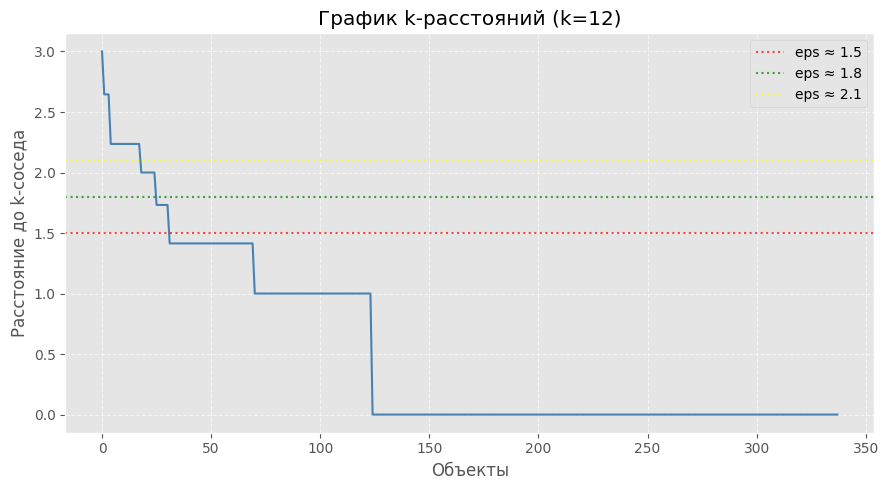

In [114]:
from sklearn.neighbors import NearestNeighbors

k = 12
dist = NearestNeighbors(n_neighbors=k).fit(df).kneighbors(df)[0][:, -1]

plt.figure(figsize=(9, 5))
plt.plot(sorted(dist, reverse=True), color='steelblue', linewidth=1.5)
plt.xlabel('Объекты')
plt.ylabel('Расстояние до k-соседа')
plt.title('График k-расстояний (k=12)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(y=1.5, color='red', linestyle=':', alpha=0.7, label='eps ≈ 1.5')
plt.axhline(y=1.8, color='green', linestyle=':', alpha=0.7, label='eps ≈ 1.8')
plt.axhline(y=2.1, color='yellow', linestyle=':', alpha=0.7, label='eps ≈ 2.1')
plt.legend()
plt.tight_layout()
plt.show()

### Визуализация

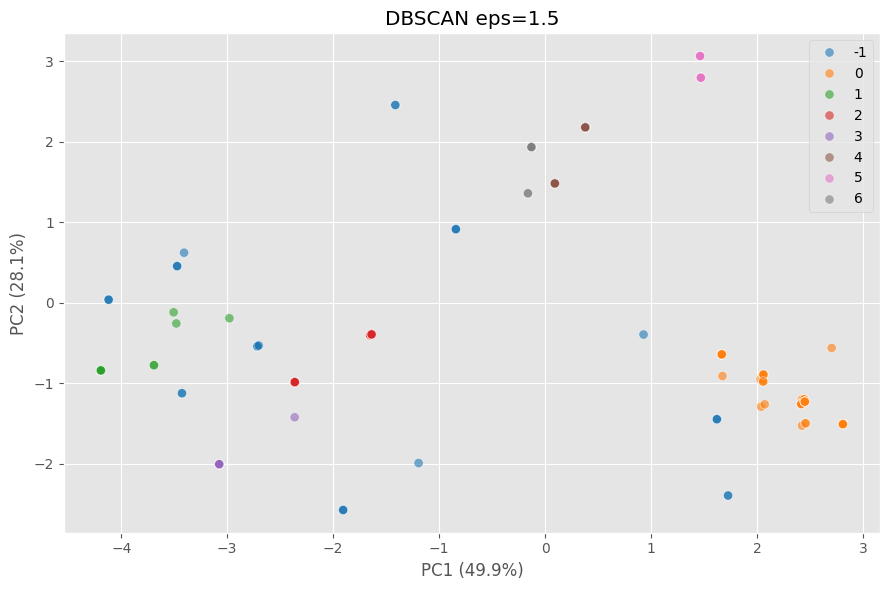

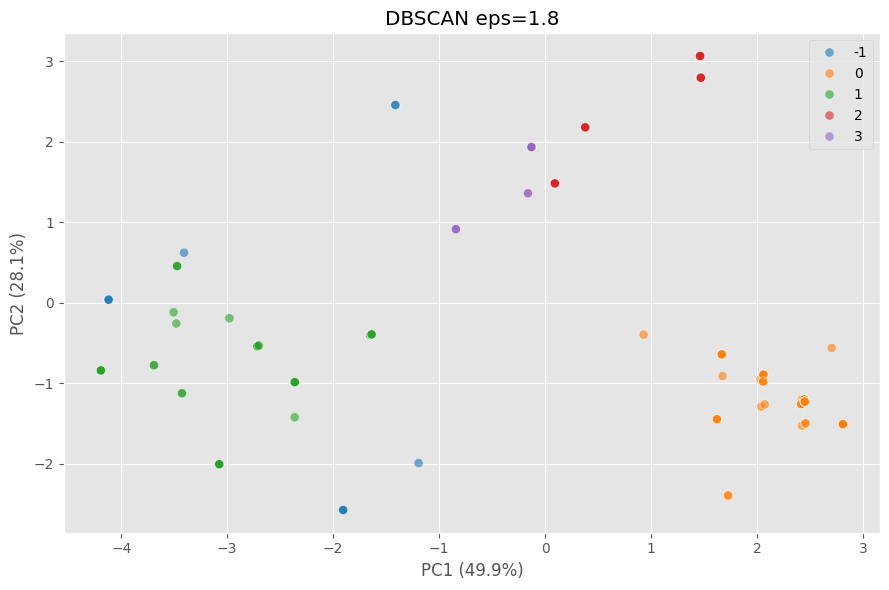

In [118]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2, random_state=42)
x = pca.fit_transform(df)

# eps = 1.5
plt.figure(figsize=(9, 6))
sns.scatterplot(x=x[:, 0], y=x[:, 1], hue=dbscan_6.labels_,
                palette='tab10', s=45, alpha=0.6)
plt.title('DBSCAN eps=1.5')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.tight_layout(); plt.show()

# eps = 1.8
plt.figure(figsize=(9, 6))
sns.scatterplot(x=x[:, 0], y=x[:, 1], hue=dbscan_4.labels_,
                palette='tab10', s=45, alpha=0.6)
plt.title('DBSCAN eps=1.8')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.tight_layout(); plt.show()

In [130]:
score1 = silhouette_score(df, dbscan_4.labels_)
score2 = silhouette_score(df, dbscan_5.labels_)
score3 = silhouette_score(df, dbscan_6.labels_)
print(f'eps = 1.8: sil = {score1}')
print(f'eps = 2.1: sil = {score2}')
print(f'eps = 1.5: sil = {score3}')

eps = 1.8: sil = 0.678146509585865
eps = 2.1: sil = 0.5603656761322348
eps = 1.5: sil = 0.7092829995285242


In [134]:
df['cluster_dbscan'] = dbscan_4.labels_
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,cluster_dbscan
0,4,5,5,5,3,3,3,3,3,3,3,0
1,5,4,5,5,3,3,3,3,3,3,3,0
2,5,5,4,5,3,3,3,3,3,3,3,0
3,5,4,5,5,3,3,3,3,3,3,3,0
4,4,5,5,5,3,3,3,3,3,3,3,0


In [135]:
df.groupby('cluster_dbscan').size()

,0
cluster_dbscan,
-1,10
0,110
1,100
2,61
3,57


In [138]:
df.groupby('cluster_dbscan').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster_dbscan,,,,,,,,,,,
-1,2.200000,2.80,2.800000,2.800000,2.000000,2.200000,3.400000,3.800000,4.600000,4.400000,4.400000
0,4.845455,4.80,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
1,2.890000,2.82,2.750000,2.590000,2.660000,2.630000,2.730000,2.870000,4.950000,4.820000,4.870000
2,3.000000,3.00,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098
3,3.000000,3.00,3.000000,2.947368,2.947368,2.947368,4.912281,4.912281,3.000000,3.000000,3.000000


Кластер 1 (100 человек, 29.7%) - потребители приобретают леденцы для здоровья.

Кластер 2 (110 человек, 32.5%) - потребители приобретают леденцы для уверенности и свежести дыхания в полости рта.

Кластер 3 (57 человек, 17.5%) - потребители приобретают леденцы для концентрации.

Кластер 4 (61 человек, 17%) - потребители приобретают леденцы, так как они им нравятся как сладость.